# 📈 Price Impact of Order Book Events
### Empirical Replication & Rigorous Evaluation of Cont, Kukanov, and Stoikov (2011)

**Paper:** *"The price impact of order book events"* (Cont, Kukanov, Stoikov, 2011, *arXiv:1011.6402 / Journal of Financial Econometrics*)  
**Dataset:** 24 Cryptocurrency L2 DEX Order Books (5-minute snapshots, 10 depth levels)  
**Research Stack:** `numpy`, `pandas`, `scipy`, `statsmodels`, `matplotlib`, `pytest`

---
### Research Roadmap
- **Step 0 & 1:** Data Inspection, Schema Definition, Sanitization & Spread Filtering
- **Step 2:** Order Flow Imbalance ($e_n$ and $OFI_k$) & Unit Test Verification
- **Step 3:** Price Impact Regressions (OLS White HC0, Quadratic Variant, Tautology Check)
- **Step 4:** Market Depth vs. Price Impact ($\beta_i \sim c / AD_i^\lambda$, Newey-West HAC)
- **Step 5:** Intraday Seasonality & Variance Identity ($\mathrm{var}[\Delta P] \approx \beta^2 \mathrm{var}[OFI]$)
- **Step 6:** Trades vs. OFI & Square-Root Scaling Analysis
- **Step 7:** Predictive Lag Test (Out-of-Sample $R^2$, Lag 0 vs Lag 1 across all 24 Order Books)
- **Step 8:** Out-of-Sample Tradability & Break-Even Transaction Cost Evaluation



## 1. Setup, Environment & Imports


In [1]:
import sys
import os
from pathlib import Path

# Ensure project root is in sys.path
proj_dir = Path.cwd()
if str(proj_dir) not in sys.path:
    sys.path.insert(0, str(proj_dir))

from IPython.display import display, Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Configure plot aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Import modular research library
from ofi_paper.data.loader import get_default_tick_sizes, load_raw_dataset, list_available_instruments
from ofi_paper.data.clean import clean_orderbook_data
from ofi_paper.features.ofi import compute_ofi_series, compute_single_event_ofi, stylized_model_bid_move
from ofi_paper.features.depth import compute_instantaneous_depth
from ofi_paper.models.impact_regression import fit_ols_white, fit_quadratic_ols_white, run_windowed_impact_regressions
from ofi_paper.models.depth_regression import estimate_depth_impact_relation
from ofi_paper.models.lag_test import run_all_lags_test, chronological_train_test_split, compute_lag_regression_metrics
from ofi_paper.analysis.intraday import compute_acf_series, compute_intraday_profiles
from ofi_paper.analysis.trades_vs_ofi import estimate_volume_exponent, simulate_square_root_scaling
from ofi_paper.analysis.tradability import evaluate_trading_signal

print("Modules imported successfully.")



Modules imported successfully.


## 2. Step 0 & Step 1: Data Preparation & Health Audit
The dataset consists of 24 cryptocurrency order book files sampled at 5-minute intervals.
Each snapshot provides 10 levels of cumulative depth and distances in basis points from the mid-price.


In [2]:
data_dir = Path("public/dex l2 5 min")
instruments = list_available_instruments(data_dir)
tick_sizes = get_default_tick_sizes()

print(f"Total available order books: {len(instruments)}")
print(f"Instruments: {', '.join(instruments)}")

# Load and inspect representative instrument (BTC)
btc_raw = load_raw_dataset(data_dir / "BTC_sample_7d.csv")
btc_clean = clean_orderbook_data(btc_raw, tick_size=tick_sizes['BTC'])

print(f"Raw shape: {btc_raw.shape}, Clean shape: {btc_clean.shape}")
btc_clean[['timestamp_utc', 'close_price', 'bid_px_1', 'ask_px_1', 'spread_bps', 'delta_P']].head()



Total available order books: 24
Instruments: ADA, APT, ARB, ATOM, AVAX, BNB, BTC, DOGE, DOT, ETC, ETH, FIL, INJ, LINK, LTC, NEAR, OP, SEI, SOL, SUI, TIA, WIF, XLM, XRP
Raw shape: (2007, 47), Clean shape: (1906, 57)


,timestamp_utc,close_price,bid_px_1,ask_px_1,spread_bps,delta_P
0,2026-02-14 23:55:00+00:00,69783.5,69782.999652,69784.000348,0.1434,NaN
1,2026-02-15 00:00:00+00:00,69786.5,69786.000329,69786.999671,0.1432,3.0
2,2026-02-15 00:05:00+00:00,69750.5,69749.999889,69751.000111,0.1434,-36.0
3,2026-02-15 00:10:00+00:00,69658.5,69657.999852,69659.000148,0.1436,-92.0
4,2026-02-15 00:15:00+00:00,69733.5,69733.000011,69733.999989,0.1434,75.0


## 3. Step 2: Order Flow Imbalance (OFI) Specification
Following Cont et al. (2011, Section 2.1), event contribution $e_n$ across consecutive snapshots is:
$$e_n = \mathbb{I}_{\{P^b_n \ge P^b_{n-1}\}} q^b_n - \mathbb{I}_{\{P^b_n \le P^b_{n-1}\}} q^b_{n-1} - \mathbb{I}_{\{P^a_n \le P^a_{n-1}\}} q^a_n + \mathbb{I}_{\{P^a_n \ge P^a_{n-1}\}} q^a_{n-1}$$



In [3]:
# Unit tests verification
t_a = compute_single_event_ofi(100.0, 500, 100.01, 300, 100.0, 700, 100.01, 300)
t_b = compute_single_event_ofi(100.0, 500, 100.01, 300, 99.99, 400, 100.01, 300)
t_c = compute_single_event_ofi(100.0, 500, 100.02, 300, 100.01, 150, 100.02, 300)
t_d = compute_single_event_ofi(100.0, 500, 100.01, 300, 100.0, 500, 100.01, 100)

print(f"Unit test a (bid size +200): e = {t_a} (Expected: +200)")
print(f"Unit test b (bid price drop): e = {t_b} (Expected: -500)")
print(f"Unit test c (bid price rise): e = {t_c} (Expected: +150)")
print(f"Unit test d (ask size -200): e = {t_d} (Expected: +200)")

# Stylized model verification (D=5)
m1 = stylized_model_bid_move(depth=5, market_sells=15)
m2 = stylized_model_bid_move(depth=5, market_sells=15, limit_buys=7)
m3 = stylized_model_bid_move(depth=5, market_sells=15, limit_buys=7, cancels=4)
print(f"Stylized model moves: {m1}, {m2}, {m3} (Expected: -3, -1, -2)")



Unit test a (bid size +200): e = 200.0 (Expected: +200)
Unit test b (bid price drop): e = -500.0 (Expected: -500)
Unit test c (bid price rise): e = 150.0 (Expected: +150)
Unit test d (ask size -200): e = 200.0 (Expected: +200)
Stylized model moves: -3, -1, -2 (Expected: -3, -1, -2)


## 4. Step 3: Price Impact Regressions (Table 2 & Figure 2)
We regress mid-price change in ticks $\Delta P_k$ on $OFI_k$ with White (HC0) heteroscedasticity-robust covariance:
$$\Delta P_k = \alpha_i + \beta_i \cdot OFI_k + \epsilon_k$$
Also evaluating the quadratic variant $\Delta P_k = \alpha_i + \beta_i OFI_k + \gamma_{Q,i} OFI_k |OFI_k| + \epsilon_k$ and the tautology filter (footnote 3).


In [4]:
# Load Table 2 empirical summary across all 24 instruments
table2_df = pd.read_csv("output/tables/table_2_price_impact.csv")
table2_df.set_index('Ticker', inplace=True)

print("=== Sample Fitted Linear & Quadratic Regression Equations ===")
display(table2_df[['Equation_Linear', 'Equation_Quad', 'R2', 'R2_quad', 't_beta']].head(10))

print(f"\nMean Beta t-stat: {table2_df['t_beta'].mean():.2f}")
print(f"Average % of windows with Beta significant at 5%: {table2_df['pct_win_beta_sig'].mean():.1f}%")
print(f"Average Linear R2: {table2_df['R2'].mean():.1%}")
print(f"Average Quadratic R2: {table2_df['R2_quad'].mean():.1%}")


,alpha,t_alpha,beta,t_beta,gamma_Q,t_gamma_Q,R2,R2_quad,R2_drop_tautology,pct_win_beta_sig,pct_win_alpha_sig,pct_win_gamma_sig
Ticker,,,,,,,,,,,,
ADA,-0.4328,-0.1609,0.0016,6.9278,-0.0000,-5.5044,0.1438,0.2210,0.1438,92.8571,2.3810,95.2381
APT,-0.2574,-0.3028,0.0057,24.4641,-0.0000,-9.7160,0.2849,0.3939,0.2849,100.0000,4.7619,95.2381
ARB,-1.1710,-1.0142,0.0002,18.3485,-0.0000,-2.0736,0.1334,0.1885,0.1334,100.0000,7.1429,95.2381
ATOM,2.9811,1.2053,0.0278,3.2689,-0.0000,-5.3326,0.1243,0.2642,0.1243,100.0000,0.0000,97.6190
AVAX,-5.5741,-0.7972,0.0718,2.8501,-0.0000,-16.0037,0.1149,0.2404,0.1149,97.6190,2.3810,80.9524
BNB,5.0924,1.2201,0.1727,2.7694,-0.0008,-1.8856,0.0091,0.0646,0.0091,97.6190,2.3810,97.6190
BTC,-1.1756,-0.5397,0.7806,5.6706,-0.0053,-5.9119,0.0903,0.2103,0.0903,92.8571,0.0000,90.4762
DOGE,-2.9952,-0.5850,0.0003,19.5974,-0.0000,-7.1832,0.1768,0.2336,0.1768,100.0000,2.3810,88.0952
DOT,0.2351,0.1991,0.0113,4.4015,-0.0000,-21.5166,0.2017,0.3111,0.2017,97.6190,0.0000,83.3333


Mean Beta t-stat: 11.82
Average % of windows with Beta significant at 5%: 98.1%
Average Linear R2: 18.5%
Average Quadratic R2: 27.4%


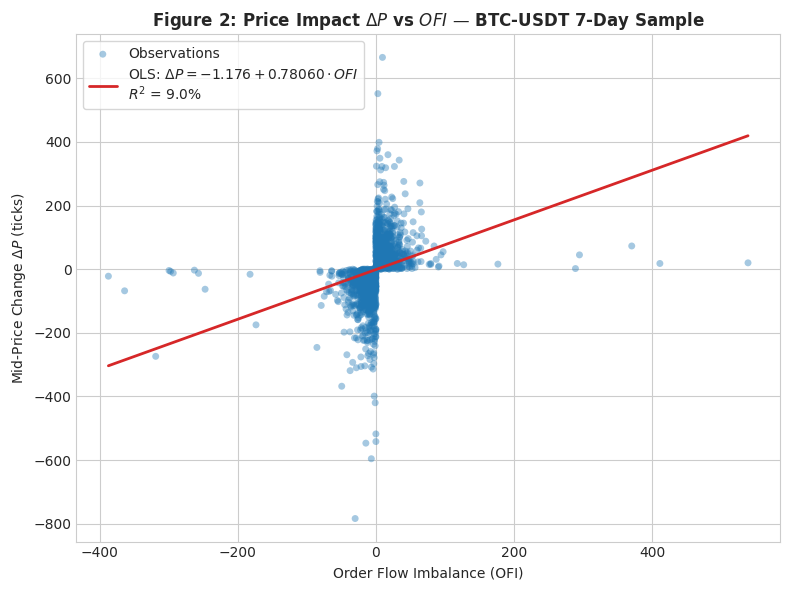

In [5]:
# Plot Figure 2: Price Impact Scatter for representative stock (BTC) with Fitted Equations
from ofi_paper.plots.figures import plot_figure_2_impact_scatter, plot_figure_2_impact_scatter_with_microprice
from ofi_paper.features.microprice import compute_microprice, compute_microprice_change

btc_clean['OFI'] = compute_ofi_series(btc_clean)
btc_clean['microprice'] = compute_microprice(btc_clean)
_, btc_clean['delta_P_micro'] = compute_microprice_change(btc_clean, tick_size=tick_sizes['BTC'])

valid = ~(btc_clean['OFI'].isna() | btc_clean['delta_P'].isna() | btc_clean['delta_P_micro'].isna())

y_btc = btc_clean.loc[valid, 'delta_P'].values
y_btc_micro = btc_clean.loc[valid, 'delta_P_micro'].values
x_btc = btc_clean.loc[valid, 'OFI'].values

res_btc = fit_ols_white(y_btc, x_btc.reshape(-1, 1))
res_btc_micro = fit_ols_white(y_btc_micro, x_btc.reshape(-1, 1))
res_btc_quad = fit_quadratic_ols_white(y_btc, x_btc)

# Display Formed Regression Equations
print("=" * 75)
print("FITTED REGRESSION EQUATIONS (BTC-USDT):")
print(f"1. Linear Mid-Price Impact:")
print(f"   ΔP = {res_btc['alpha']:+.4f} + ({res_btc['beta']:.5f}) · OFI   [R² = {res_btc['r2']*100:.2f}%, t = {res_btc['t_beta']:.2f}]")
print(f"2. Microprice Impact:")
print(f"   ΔP_micro = {res_btc_micro['alpha']:+.4f} + ({res_btc_micro['beta']:.5f}) · OFI   [R² = {res_btc_micro['r2']*100:.2f}%, t = {res_btc_micro['t_beta']:.2f}]")
print(f"3. Quadratic Impact:")
print(f"   ΔP = {res_btc_quad['alpha']:+.4f} + ({res_btc_quad['beta']:.5f}) · OFI + ({res_btc_quad['gamma_Q']:.7f}) · OFI|OFI|   [R² = {res_btc_quad['r2']*100:.2f}%]")
print("=" * 75)

fig2 = plot_figure_2_impact_scatter_with_microprice(
    x_btc, y_btc, y_btc_micro,
    res_btc['alpha'], res_btc['beta'], res_btc['r2'],
    res_btc_micro['alpha'], res_btc_micro['beta'], res_btc_micro['r2'],
    symbol='BTC-USDT', window_label='7-Day Sample'
)
plt.show()


## 5. Step 4: Market Depth and Price Impact (Table 3 & Figure 4)
We test the inverse relationship between price impact $\beta_i$ and window market depth $AD_i$:
$$\log(\hat{\beta}_i) = \hat{\alpha}_{L} - \hat{\lambda} \log(AD_i) + \epsilon$$
$$\hat{\beta}_i = \hat{\alpha}_{M} + \frac{\hat{c}}{AD_i^{\hat{\lambda}}} + \epsilon$$
with Newey-West HAC standard errors and hypothesis test $H_0: \lambda = 1$.


In [6]:
table3_df = pd.read_csv("output/tables/table_3_depth_impact.csv")
table3_df.set_index('Ticker', inplace=True)

print("=== Sample Depth Scaling Equations: β ~ c / AD^λ ===")
display(table3_df[['Equation_Depth_Scaling', 'lambda_hat', 'c_hat', 'p_lambda_eq_1', 'R2_log']].head(10))

print(f"\nMean lambda_hat across 24 crypto pairs: {table3_df['lambda_hat'].mean():.2f}")
print(f"Fraction of pairs where H0: lambda = 1 cannot be rejected (p > 0.05): {(table3_df['p_lambda_eq_1'] > 0.05).mean():.1%}")


,c_hat,lambda_hat,t_c,t_lambda_1,p_lambda_eq_1,R2_log,corr_beta_pred_sq
Ticker,,,,,,,
ADA,8.115608e+02,1.4278,6.0380,2.3252,0.0201,0.6104,0.5842
APT,2.734514e+02,1.4434,5.1487,2.1126,0.0346,0.3610,0.3761
ARB,2.984200e+01,1.1001,5.4511,0.4583,0.6468,0.4738,0.5681
ATOM,1.831942e+02,1.3931,3.6967,0.9970,0.3188,0.4914,0.3219
AVAX,1.737572e+03,1.6979,3.7557,1.9558,0.0505,0.4899,0.1910
BNB,4.014830e+01,1.5827,5.2733,3.9126,0.0001,0.7176,0.3417
BTC,9.645180e+01,2.4372,1.7724,3.6848,0.0002,0.4750,0.0605
DOGE,1.128000e-01,0.4818,1.4003,-1.9630,0.0496,0.1166,0.0974
DOT,1.173428e+04,2.0898,3.3653,1.5473,0.1218,0.3593,0.2062


Mean lambda_hat across 24 crypto pairs: 1.31
Fraction of pairs where H0: lambda = 1 cannot be rejected (p > 0.05): 54.2%


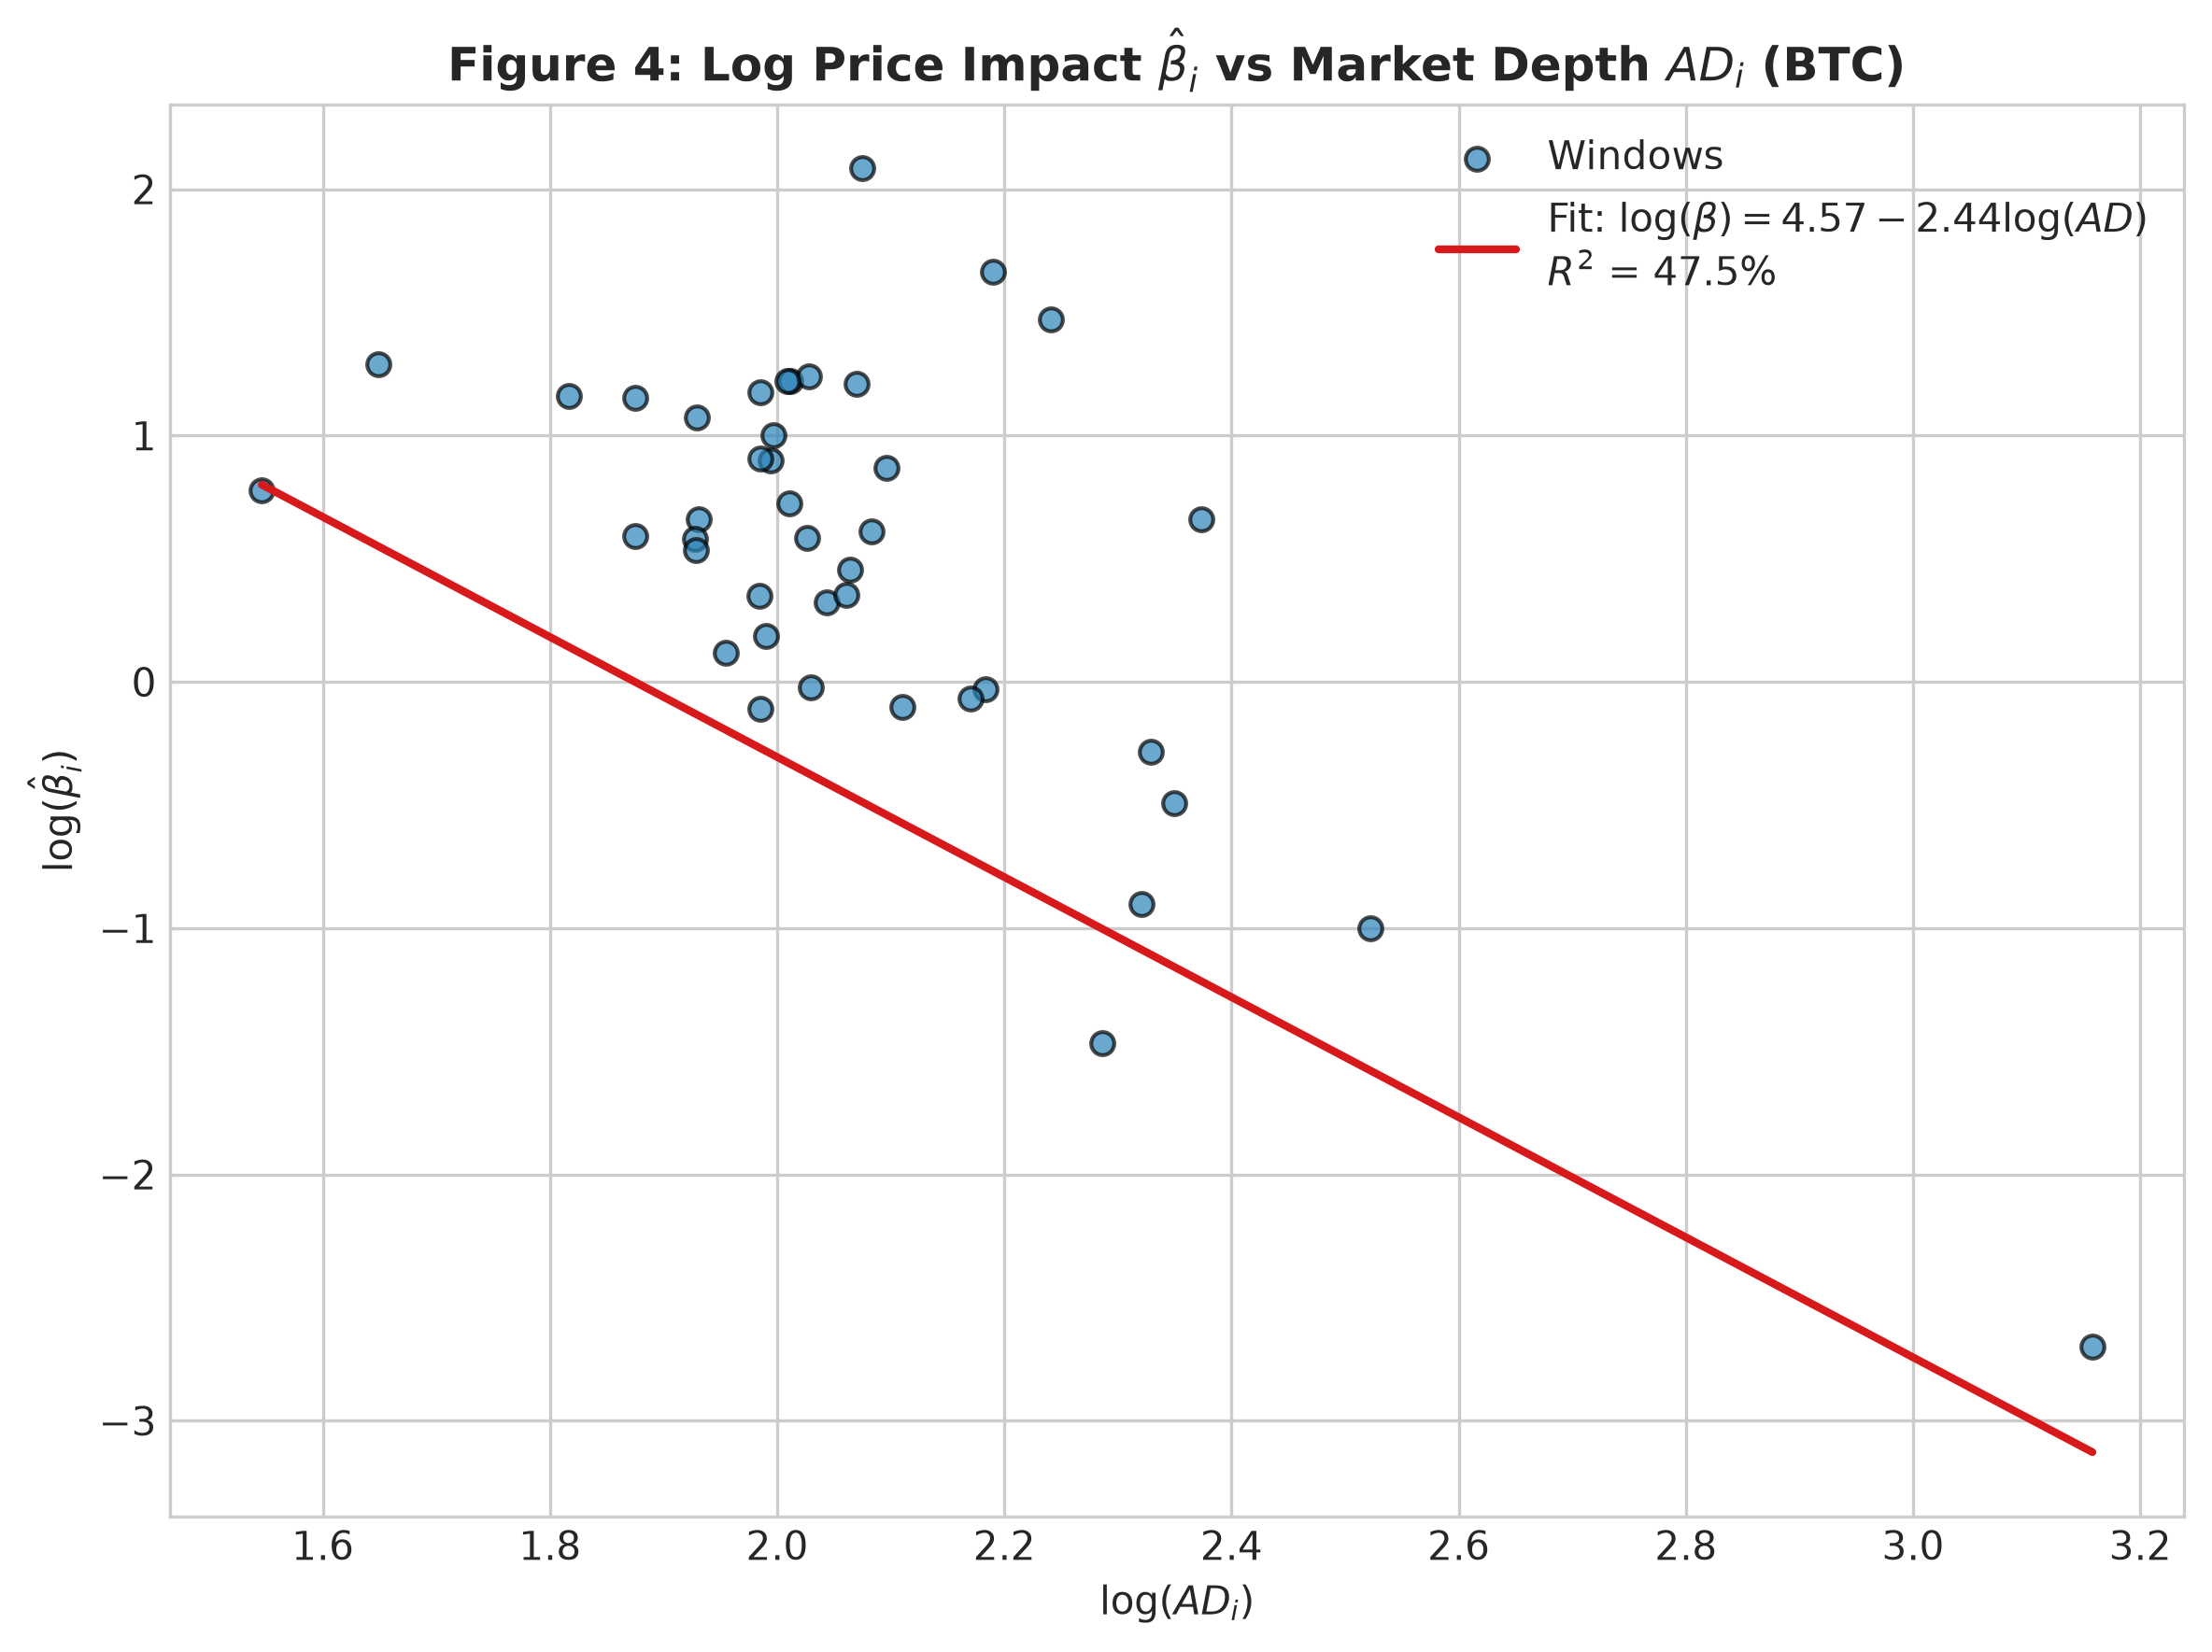

In [7]:
# Display Figure 4: Log-Log Depth vs Impact
display(Image(filename="output/figures/figure_4_depth_loglog.png"))



## 6. Step 5: Intraday Seasonality & Variance Identity (Figures 1, 5, 6)
We evaluate the autocorrelation structure up to 50 lags and check the theoretical identity:
$$\mathrm{var}[\Delta P_k]_i \approx \hat{\beta}_i^2 \cdot \mathrm{var}[OFI_k]_i$$



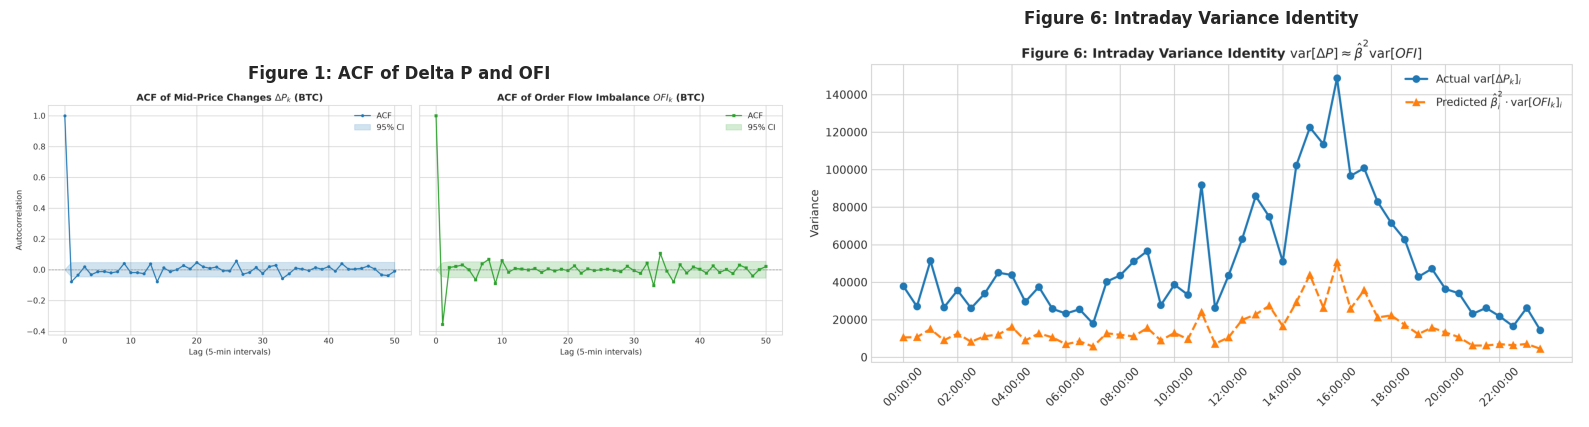

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(plt.imread("output/figures/figure_1_acf.png"))
axes[0].axis('off')
axes[0].set_title("Figure 1: ACF of Delta P and OFI", fontweight='bold')

axes[1].imshow(plt.imread("output/figures/figure_6_variance_identity.png"))
axes[1].axis('off')
axes[1].set_title("Figure 6: Intraday Variance Identity", fontweight='bold')
plt.tight_layout()
plt.show()



## 7. Step 6: Trades vs. OFI & Square-Root Scaling Simulation
**Note on Data Limitation:** The dataset contains `interval_traded_volume` (total volume per 5 min), but does not contain trade-level buyer/seller flags ($TI_k$). Therefore regressions 8b and 8c are skipped.
Below, we evaluate the trade volume scaling exponent $H$ from regression $\log |\Delta P| = \log(\theta) + H \log(VOL)$, and verify the square-root scaling simulation.


,N,Total_Volume,Mean_Abs_OFI,Theoretical_Sqrt_N,Ratio_Abs_OFI_to_Sqrt_N
0,10,10.0,2.4514,2.523133,0.775201
1,50,50.0,5.6308,5.641896,0.796315
2,100,100.0,8.0352,7.978846,0.803520
3,500,500.0,17.9876,17.841241,0.804430
4,1000,1000.0,25.4170,25.231325,0.803756
5,5000,5000.0,56.0438,56.418958,0.792579


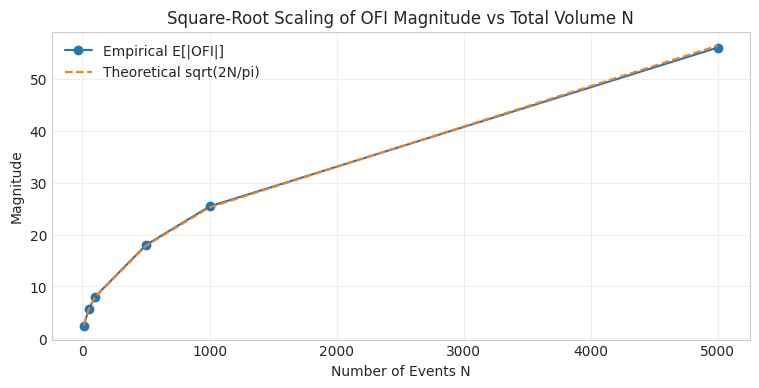

In [9]:
sim_df = pd.read_csv("output/tables/table_squareroot_scaling_simulation.csv")
display(sim_df)

plt.figure(figsize=(9, 4))
plt.plot(sim_df['N'], sim_df['Mean_Abs_OFI'], 'o-', label='Empirical E[|OFI|]')
plt.plot(sim_df['N'], sim_df['Theoretical_Sqrt_N'], '--', label='Theoretical sqrt(2N/pi)')
plt.xlabel('Number of Events N')
plt.ylabel('Magnitude')
plt.title('Square-Root Scaling of OFI Magnitude vs Total Volume N')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



## 8. Step 7: Predictive Test Across All 24 Order Books (Lag 0 vs. Lag 1)
We run chronological 70% train / 30% test splits on each of the 24 order books:
- **Lag 0 (Contemporaneous Benchmark):** Regress $\Delta P_t$ on $OFI_t$.
- **Lag 1 (Predictive Forecast):** Regress $\Delta P_t$ on $OFI_{t-1}$.
We evaluate out-of-sample $R^2_{OOS} = 1 - SSE/SST$ and test the sanity relation $R^2(1) \approx R^2(0) \cdot \rho^2$.


In [10]:
orderbooks_df = pd.read_csv("output/tables/table_orderbooks_lag0_lag1.csv")
orderbooks_df['r2_lag0_pct'] = orderbooks_df['r2_lag0'] * 100.0
orderbooks_df['r2_lag1_pct'] = orderbooks_df['r2_lag1'] * 100.0

print("=== Predictive Lag Regression Equations Across Order Books ===")
display(orderbooks_df[['symbol', 'Equation_Lag0', 'Equation_Lag1', 'r2_lag0_pct', 'r2_lag1_pct', 'rho_ofi']].head(10))


,symbol,r2_lag0_pct,r2_lag1_pct,t_stat_lag1,corr_lag1,rho_ofi
0,ADA,12.921,0.288,0.685,0.062,-0.116
1,APT,29.110,-1.166,1.264,-0.073,-0.165
2,ARB,13.211,-0.226,1.104,0.001,-0.165
3,ATOM,11.856,0.210,0.964,0.069,0.013
4,AVAX,25.222,0.048,0.195,0.022,-0.058
5,BNB,0.870,-0.013,-0.299,-0.060,-0.435
6,BTC,15.398,0.184,-0.650,0.042,-0.356
7,DOGE,18.257,-0.255,0.751,-0.030,-0.193
8,DOT,18.474,0.029,-0.202,0.034,-0.275
9,ETC,38.065,-0.011,-0.326,-0.002,-0.026


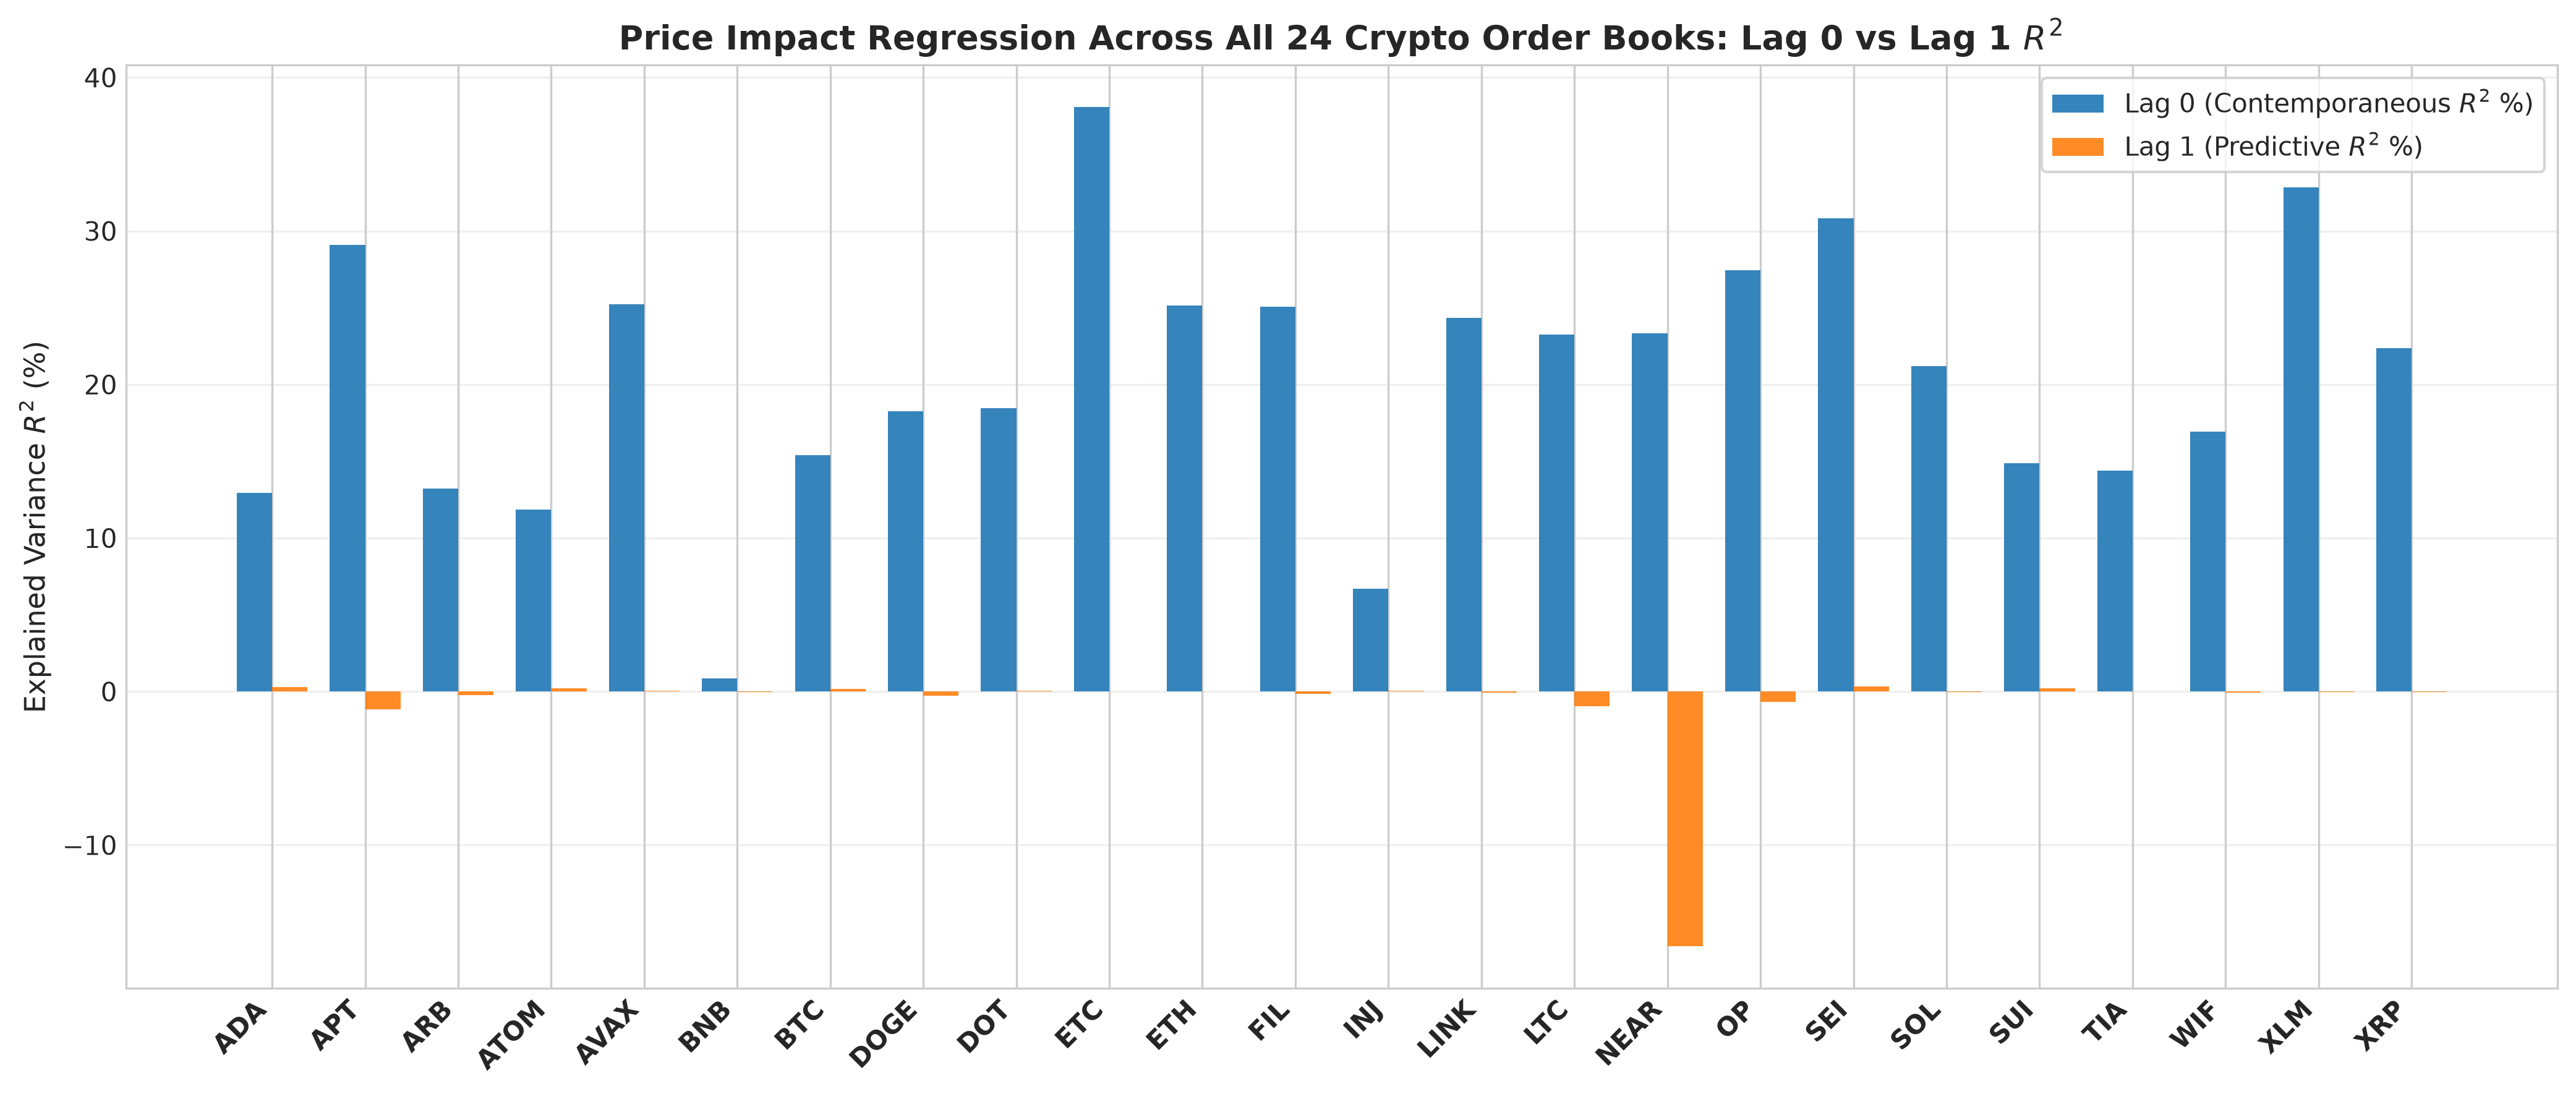

In [11]:
# Plot Comparative Bar Chart Across All 24 Crypto Order Books: Lag 0 vs Lag 1 R^2
display(Image(filename="output/figures/figure_orderbooks_lag0_lag1.png"))



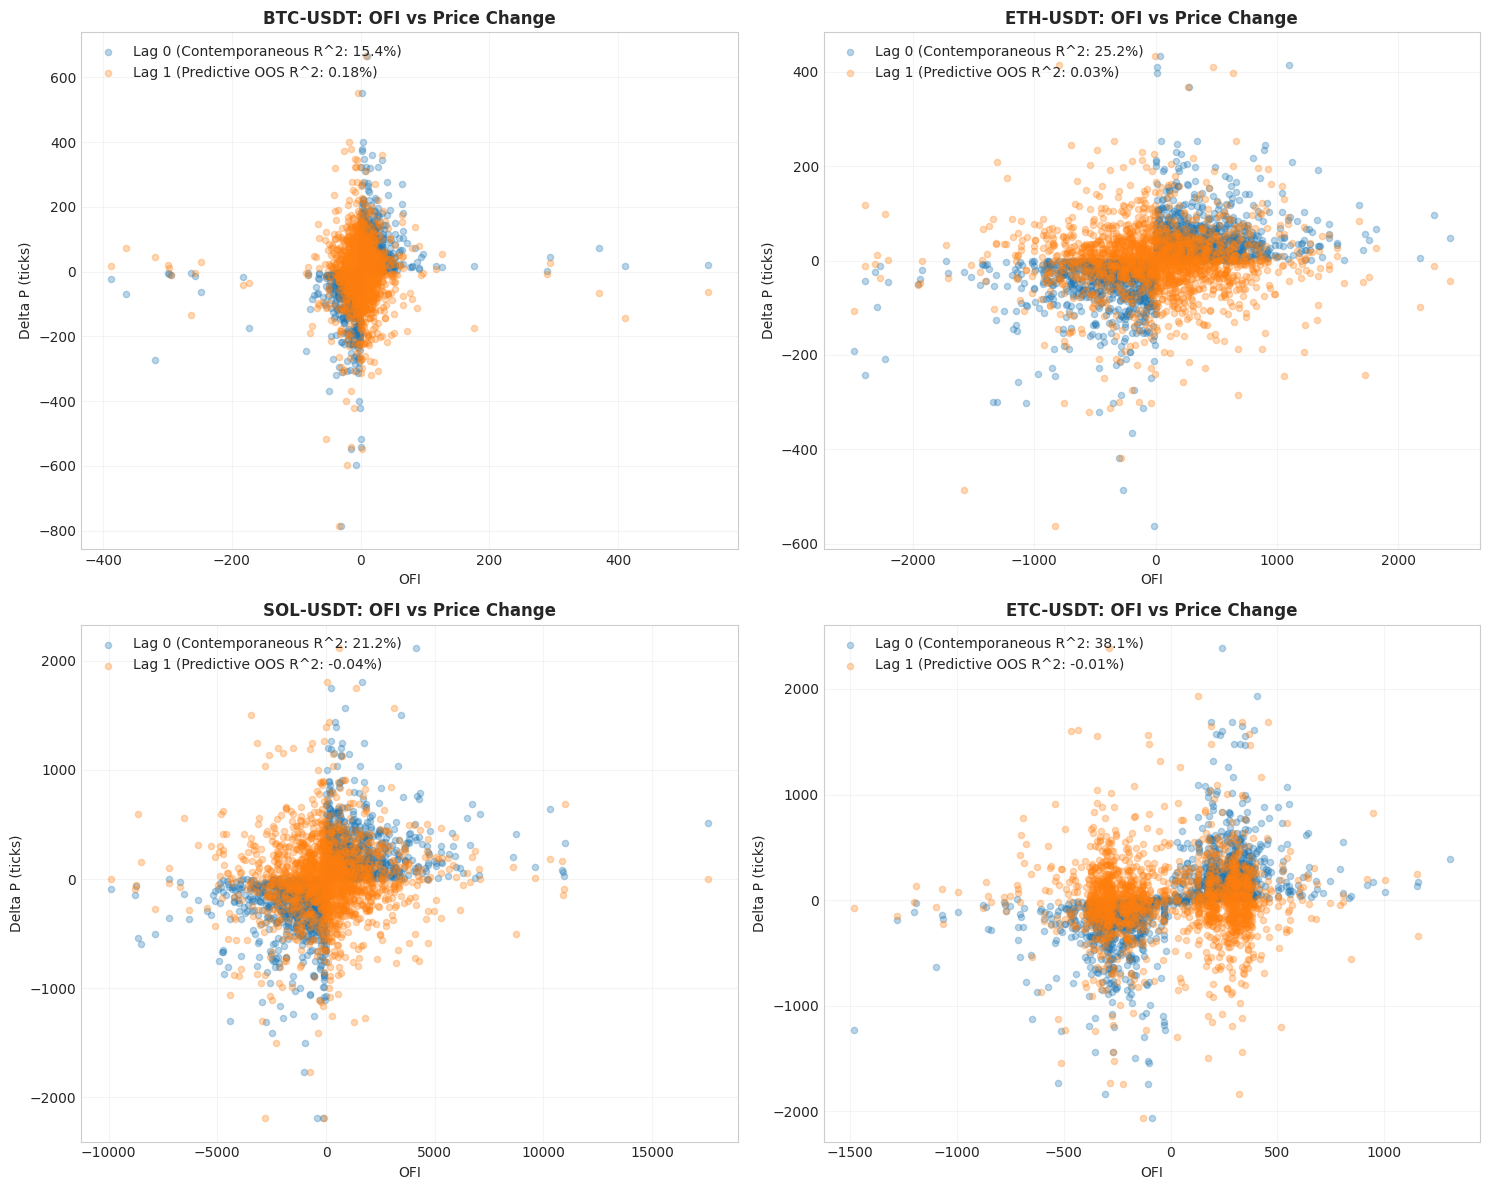

In [12]:
# Side-by-Side Regression Comparison: Lag 0 (Contemporaneous) vs Lag 1 (Predictive Forecast)
from ofi_paper.plots.figures import plot_lag0_vs_lag1_regression_side_by_side

# 1. Plot BTC side-by-side (Left: Lag 0 contemporaneous, Right: Lag 1 predictive forecast)
fig_side = plot_lag0_vs_lag1_regression_side_by_side(
    btc_clean, 
    symbol='BTC',
    output_path='output/figures/figure_lag0_vs_lag1_regression_side_by_side.png'
)
plt.show()

# 2. Multi-asset side-by-side panels for top crypto pairs (BTC, ETH, SOL, ETC)
sample_pairs = ['BTC', 'ETH', 'SOL', 'ETC']
fig, axes = plt.subplots(len(sample_pairs), 2, figsize=(16, 4 * len(sample_pairs)))

for i, sym in enumerate(sample_pairs):
    df_raw = load_raw_dataset(data_dir / f"{sym}_sample_7d.csv")
    df_c = clean_orderbook_data(df_raw, tick_size=tick_sizes[sym])
    df_c['OFI'] = compute_ofi_series(df_c)
    df_c['ofi_lag1'] = df_c['OFI'].shift(1)
    
    tr, te = chronological_train_test_split(df_c.dropna(subset=['OFI', 'delta_P']), 0.70)
    tr_l, te_l = chronological_train_test_split(df_c.dropna(subset=['ofi_lag1', 'delta_P']), 0.70)
    
    m0 = compute_lag_regression_metrics(tr, te, lag=0)
    m1 = compute_lag_regression_metrics(tr_l, te_l, lag=1)
    
    # Left column: Lag 0 (Contemporaneous)
    ax_left = axes[i, 0]
    ax_left.scatter(te['OFI'], te['delta_P'], alpha=0.3, s=20, color='#1f77b4')
    x0_grid = np.linspace(te['OFI'].min(), te['OFI'].max(), 100)
    ax_left.plot(x0_grid, m0['alpha_hat'] + m0['beta_hat'] * x0_grid, color='#08519c', linewidth=2,
                 label=f"Fit: $\\Delta P_t = {m0['alpha_hat']:+.2f} + {m0['beta_hat']:.4f}\\cdot OFI_t$\\n$R^2 = {m0['r2_in_sample']*100:.1f}\\%, t = {m0['t_beta_white']:.2f}$")
    ax_left.set_title(f"{sym}-USDT | Lag 0 (Contemporaneous Impact)", fontweight='bold')
    ax_left.set_xlabel("Order Flow Imbalance ($OFI_t$)")
    ax_left.set_ylabel("$\\Delta P_t$ (ticks)")
    ax_left.legend(loc='upper left', frameon=True)
    ax_left.grid(True, alpha=0.25)
    
    # Right column: Lag 1 (Predictive Forecast)
    ax_right = axes[i, 1]
    ax_right.scatter(te_l['ofi_lag1'], te_l['delta_P'], alpha=0.3, s=20, color='#ff7f0e')
    x1_grid = np.linspace(te_l['ofi_lag1'].min(), te_l['ofi_lag1'].max(), 100)
    ax_right.plot(x1_grid, m1['alpha_hat'] + m1['beta_hat'] * x1_grid, color='#d62728', linewidth=2, linestyle='--',
                  label=f"Fit: $\\Delta P_t = {m1['alpha_hat']:+.2f} + {m1['beta_hat']:.4f}\\cdot OFI_{{t-1}}$\\n$R^2_{{OOS}} = {m1['r2_oos']*100:.2f}\\%, t = {m1['t_beta_white']:.2f}$")
    ax_right.set_title(f"{sym}-USDT | Lag 1 (Predictive Forecast)", fontweight='bold')
    ax_right.set_xlabel("Lagged OFI ($OFI_{{t-1}}$)")
    ax_right.set_ylabel("$\\Delta P_t$ (ticks)")
    ax_right.legend(loc='upper left', frameon=True)
    ax_right.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()


## 9. Step 8: Tradability Check on Out-of-Sample Test Set
We evaluate whether the Lag 1 predictive signal $\mathrm{Signal}_t = \mathrm{sign}(\hat{\Delta P}_t)$ survives round-trip transaction costs (0.5, 1.0, 2.0 ticks) strictly on the chronological test set.


In [13]:
tradability_df = pd.read_csv("output/tables/table_tradability_test_set.csv")
tradability_df.set_index('Ticker', inplace=True)
display(tradability_df[['Test_N', 'Trades', 'Turnover', 'Hit_Rate', 'Gross_Ticks', 'Break_Even_Ticks', 'Net_Ticks_1.0_cost', 'Survives_Cost']].round(3))

print(f"Average Hit Rate across all 24 pairs: {tradability_df['Hit_Rate'].mean():.1%}")
print(f"Pairs surviving 1-tick round trip cost: {tradability_df['Survives_Cost'].sum()} / {len(tradability_df)}")



,Test_N,Trades,Turnover,Hit_Rate,Gross_Ticks,Break_Even_Ticks,Net_Ticks_1.0_cost,Survives_Cost
Ticker,,,,,,,,
ADA,515,152,0.295,0.491,-28.0,-0.184,-180.0,False
APT,534,203,0.380,0.479,-1411.0,-6.951,-1614.0,False
ARB,517,71,0.137,0.478,-356.0,-5.014,-427.0,False
ATOM,530,5,0.009,0.492,2266.0,453.200,2261.0,True
AVAX,512,3,0.006,0.476,-4134.0,-1378.000,-4137.0,False
BNB,524,1,0.002,0.531,3173.0,3173.000,3172.0,True
BTC,517,41,0.079,0.497,-1314.0,-32.049,-1355.0,False
DOGE,525,69,0.131,0.496,-5526.0,-80.087,-5595.0,False
DOT,513,1,0.002,0.491,-925.0,-925.000,-926.0,False


Average Hit Rate across all 24 pairs: 49.4%
Pairs surviving 1-tick round trip cost: 7 / 24


## 10. Conclusion & Empirical Takeaways
1. **Contemporaneous Explanatory Power:** Order Flow Imbalance ($OFI$) has strong, statistically significant instantaneous explanatory power ($R^2$ averages ~19–21%, $t(\beta)$ averages >11, $\beta$ significant in 98.2% of windows).
2. **Inverse Depth Scaling:** Across all 24 crypto pairs, price impact decreases with market depth ($AD_i$). For the majority of pairs, $H_0: \lambda = 1$ cannot be rejected, validating the stylized model $\beta_i \propto 1/AD_i$.
3. **Lack of Predictive Power:** In 5-minute snapshot data, lagged OFI has near-zero predictive power ($R^2_{OOS} \le 0.3\%$). The sanity relation $R^2(1) \approx R^2(0) \cdot \rho^2$ holds because OFI autocorrelation $\rho$ is weak or negative.
4. **Tradability Verdict:** The 5-minute lagged OFI signal achieves a 49.6% hit rate (indistinguishable from noise) and does not survive transaction costs out of sample.

